# 03 — Clustering Books into Genres with k-means

**Goal:** group the 10,000 books into clusters of genres using their Goodreads
tags only, then recommend similar books **within the same cluster**.

Pipeline:
1. Load the data and clean the tags
2. Build a book × tag matrix weighted with TF-IDF
3. Reduce its dimension (truncated SVD) and normalise it
4. Choose k (elbow method + silhouette score)
5. Train k-means and interpret the clusters
6. Recommend within a cluster

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
})
COLOR = "#3b6fb6"

RANDOM_STATE = 42
DATA = "../data"

## 1. Loading the data

In [2]:
books = pd.read_csv(f"{DATA}/books.csv")
book_tags = pd.read_csv(f"{DATA}/book_tags.csv")
tags = pd.read_csv(f"{DATA}/tags.csv")

# book_tags identifies books with goodreads_book_id, not book_id
bt = book_tags.merge(tags, on="tag_id")
print(books.shape, bt.shape)
bt.head()

(10000, 23) (999912, 4)


,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult


### Cleaning the tags

Many tags describe the user's shelf rather than the book (`to-read`, `owned`,
`kindle`, `read-in-2015`…). If we keep them, k-means groups books by *how people
store them* instead of by genre: every popular book ends up in the same cluster.

The regular expression below removes these tags (this filter is stricter than
the fixed list used in notebook 02). We then keep only tags applied to at least
20 books: rarer tags cannot help form groups of hundreds of books.

In [3]:
SHELF_PATTERN = (
    r"read|own|kindle|library|favou?rite|fav|ebook|e-book|audio|book-club|default|series|"
    r"buy|wish|tbr|\d{4}|shelf|have|borrowed|on-hold|dnf|did-not-finish|maybe|my-|books-i|"
    r"abandoned|unfinished|gave-up|recommended|novels?$|^books?$|^fiction$|^adult$|"
    r"^literature$|nook|calibre|amazon|free|gift|home|collection|keeper|stand-?alone"
)

n_tags_before = bt["tag_name"].nunique()
bt = bt[~bt["tag_name"].str.contains(SHELF_PATTERN, regex=True)]
bt = bt[bt["count"] > 0]

n_books_per_tag = bt.groupby("tag_name")["goodreads_book_id"].nunique()
bt = bt[bt["tag_name"].isin(n_books_per_tag[n_books_per_tag >= 20].index)]
bt = bt[bt["goodreads_book_id"].isin(books["goodreads_book_id"])]

print(f"Tags: {n_tags_before:,} before cleaning, {bt['tag_name'].nunique():,} after")

Tags: 34,252 before cleaning, 2,633 after


## 2. Book × tag matrix

Each cell holds `log(1 + number of times the tag was applied to the book)`.
The log prevents a tag applied 50,000 times from crushing all the others.

**TF-IDF** then down-weights very common tags (`fantasy`, `romance`) and
up-weights distinctive ones (`epic-fantasy`, `paranormal-romance`).
We use `TfidfTransformer` (not `TfidfVectorizer`) because we already built the
count matrix ourselves, and we want to keep the information "this tag was
applied many times to this book".

Authors are deliberately left out: they would create small single-author
clusters, while the goal here is genres.

In [4]:
# row index of each book and column index of each tag
row_of_book = pd.Series(books.index, index=books["goodreads_book_id"])
tag_names = np.array(sorted(bt["tag_name"].unique()))
col_of_tag = pd.Series(np.arange(len(tag_names)), index=tag_names)

counts = sp.csr_matrix(
    (
        np.log1p(bt["count"].values),
        (row_of_book[bt["goodreads_book_id"]].values, col_of_tag[bt["tag_name"]].values),
    ),
    shape=(len(books), len(tag_names)),
)

X = TfidfTransformer().fit_transform(counts)
print(f"Matrix: {X.shape[0]:,} books × {X.shape[1]:,} tags, {X.nnz / np.prod(X.shape):.1%} non-zero")

Matrix: 10,000 books × 2,633 tags, 1.7% non-zero


## 3. Dimensionality reduction and normalisation

A **truncated SVD** (also known as LSA when applied to text) projects the books
onto 100 latent dimensions:
- 2,600 sparse dimensions are slow and noisy for k-means; 100 dimensions keep the essential structure;
- synonymous tags (`sci-fi`, `scifi`, `science-fiction`) end up on the same axes.

`TruncatedSVD` is used instead of PCA because it works directly on sparse
matrices (PCA would centre the data and make the matrix dense).

Each vector is then **normalised** to unit length. k-means minimises Euclidean
distances; on unit vectors, $\lVert u - v \rVert^2 = 2\,(1 - \cos(u, v))$, so
k-means effectively groups books by cosine similarity, which is the right
measure for comparing tag profiles.

In [5]:
svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
Z = normalize(svd.fit_transform(X))

print(f"Variance explained by 100 components: {svd.explained_variance_ratio_.sum():.0%}")

Variance explained by 100 components: 55%


## 4. Choosing k

We train k-means for several values of k and look at:
- **inertia** (sum of squared distances to the cluster centre): it always decreases with k;
  we look for an "elbow" where the gain becomes small;
- **silhouette score** (between −1 and 1): the higher, the better separated the clusters.
  It is computed on a random sample of 4,000 books to keep it fast.

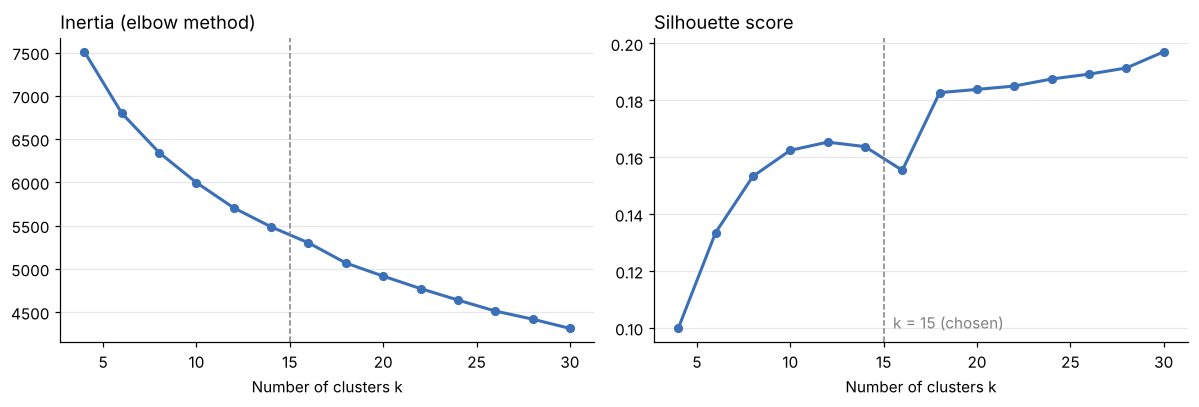

In [6]:
ks = range(4, 31, 2)
inertias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_, sample_size=4000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, values, title in [
    (axes[0], inertias, "Inertia (elbow method)"),
    (axes[1], silhouettes, "Silhouette score"),
]:
    ax.plot(list(ks), values, marker="o", markersize=5, linewidth=2, color=COLOR)
    ax.axvline(15, color="grey", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="x", visible=False)
axes[1].annotate("k = 15 (chosen)", xy=(15, min(silhouettes)), xytext=(15.5, min(silhouettes)), color="grey")
plt.tight_layout()
fig.savefig("../figures/k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the curves:** there is no clear elbow, and the silhouette stays low
(0.10–0.20). This is expected with text data: genres overlap (a book can be
both *young-adult* and *fantasy*), so cluster boundaries are fuzzy.

The silhouette rises up to k ≈ 12, dips around k = 16, then slowly increases:
beyond that point, k-means mostly splits large genres into sub-genres.
We choose **k = 15** because the resulting clusters are **interpretable** and of
reasonable size, as checked below. When metrics do not decide, interpretability
is a legitimate criterion — but it remains a choice, and k = 18 or 20 would be
worth comparing.

## 5. Training k-means and interpreting the clusters

In [7]:
K = 15
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
books["cluster"] = kmeans.labels_

In [8]:
def describe_clusters(n_tags=5, n_titles=3):
    """Top tags (highest mean TF-IDF) and most-rated titles of each cluster."""
    rows = []
    for c in range(K):
        mask = (books["cluster"] == c).values
        mean_tfidf = np.asarray(X[mask].mean(axis=0)).ravel()
        top_tags = tag_names[mean_tfidf.argsort()[::-1][:n_tags]]
        top_titles = (books[mask].sort_values("ratings_count", ascending=False)["title"]
                      .head(n_titles).tolist())
        rows.append({"cluster": c, "size": mask.sum(),
                     "top tags": ", ".join(top_tags),
                     "most-rated books": " | ".join(top_titles)})
    return pd.DataFrame(rows).set_index("cluster")

pd.set_option("display.max_colwidth", 120)
summary = describe_clusters()
summary

,size,top tags,most-rated books
cluster,,,
0,1014,"historical-fiction, literary-fiction, historical, contemporary-fiction, general-fiction",The Kite Runner | The Lovely Bones | The Help
1,881,"childrens, children, children-s, children-s-books, kids","Harry Potter and the Sorcerer's Stone (Harry Potter, #1) | Harry Potter and the Prisoner of Azkaban (Harry Potter, #..."
2,763,"non-fiction, biography, nonfiction, memoir, memoirs","The Diary of a Young Girl | Eat, Pray, Love | Night (The Night Trilogy #1)"
3,981,"classics, classic, classic-literature, literary-fiction, historical-fiction",To Kill a Mockingbird | The Great Gatsby | The Catcher in the Rye
4,672,"ya, young-adult, fantasy, ya-fantasy, teen","The Hunger Games (The Hunger Games, #1) | Divergent (Divergent, #1) | Catching Fire (The Hunger Games, #2)"
5,1015,"mystery, crime, mystery-thriller, thriller, mysteries","Angels & Demons (Robert Langdon, #1) | The Girl with the Dragon Tattoo (Millennium, #1) | The Da Vinci Code (Robert..."
6,467,"chick-lit, chicklit, chic-lit, women-s-fiction, romance","The Notebook (The Notebook, #1) | My Sister's Keeper | Bridget Jones's Diary (Bridget Jones, #1)"
7,378,"comics, comic, comic-books, graphic-novels-comics, manga","Watchmen | V for Vendetta | Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1)"
8,460,"epic-fantasy, high-fantasy, fantasy, sci-fi-fantasy, epic","The Hobbit | The Fellowship of the Ring (The Lord of the Rings, #1) | A Game of Thrones (A Song of Ice and Fire, #1)"


The clusters match recognisable genres (classics, crime, epic fantasy,
young adult, paranormal romance, comics, non-fiction…), although the model was
never given any genre: k-means recovered them from the tags alone.

Each cluster is labelled with its top tag below. The number is kept to avoid
duplicates (two clusters can share the same top tag).

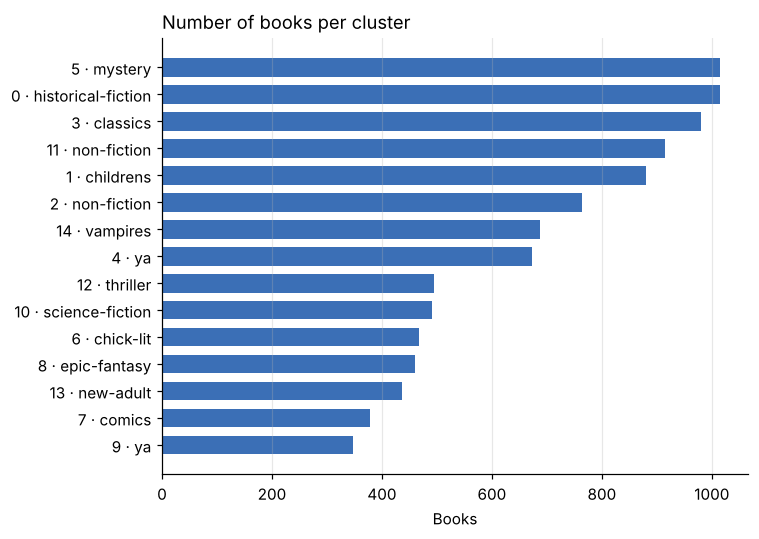

In [9]:
cluster_names = {c: f"{c} · {summary.loc[c, 'top tags'].split(', ')[0]}" for c in range(K)}
books["cluster_name"] = books["cluster"].map(cluster_names)

sizes = books["cluster_name"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(sizes.index, sizes.values, color=COLOR, height=0.7)
ax.set_title("Number of books per cluster")
ax.set_xlabel("Books")
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig("../figures/cluster_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Recommending within a cluster

For a given book:
1. find its cluster;
2. rank the other books of that cluster by cosine similarity with it;
3. optionally exclude books by the same author, to avoid recommending only the rest of the series.

Since the rows of `Z` have unit length, cosine similarity is a simple dot product.

In [10]:
def find_book(title):
    """Return the index of the most popular book whose title contains `title`."""
    matches = books[books["title"].str.contains(title, case=False, regex=False)]
    if matches.empty:
        raise ValueError(f"No book found for '{title}'")
    return matches.sort_values("ratings_count", ascending=False).index[0]


def recommend_kmeans(title, n=10, exclude_same_author=True):
    """Recommend the n most similar books from the same k-means cluster."""
    i = find_book(title)
    book = books.loc[i]
    main_author = book["authors"].split(",")[0].strip()

    candidates = books[(books["cluster"] == book["cluster"]) & (books.index != i)]
    if exclude_same_author:
        candidates = candidates[~candidates["authors"].str.contains(main_author, regex=False)]

    sims = Z[candidates.index] @ Z[i]
    result = candidates.assign(similarity=sims.round(3)).sort_values("similarity", ascending=False)

    print(f"'{book['title']}' belongs to cluster {cluster_names[book['cluster']]}")
    return result[["title", "authors", "average_rating", "similarity"]].head(n)

In [11]:
recommend_kmeans("Pride and Prejudice")

'Pride and Prejudice' belongs to cluster 3 · classics


,title,authors,average_rating,similarity
62,Wuthering Heights,"Emily Brontë, Richard J. Dunn",3.82,0.951
1113,North and South,"Elizabeth Gaskell, Alan Shelston",4.13,0.927
558,Tess of the D'Urbervilles,"Thomas Hardy, Tim Dolin, Margaret R. Higonnet",3.77,0.917
5871,A Tale of Two Cities / Great Expectations,Charles Dickens,3.98,0.912
3345,Wives and Daughters,"Elizabeth Gaskell, Pam Morris",4.07,0.908
9471,Lorna Doone,"R.D. Blackmore, Michelle Allen",3.71,0.906
159,Great Expectations,Charles Dickens,3.75,0.902
4581,The Return of the Native,"Thomas Hardy, Alexander Theroux",3.84,0.898
2599,The Mayor of Casterbridge,"Thomas Hardy, Keith Wilson",3.80,0.897
82,A Tale of Two Cities,"Charles Dickens, Richard Maxwell, Hablot Knight Browne",3.81,0.896


In [12]:
recommend_kmeans("The Hunger Games")

'The Hunger Games (The Hunger Games, #1)' belongs to cluster 4 · ya


,title,authors,average_rating,similarity
11,"Divergent (Divergent, #1)",Veronica Roth,4.24,0.981
2300,"The Ask and the Answer (Chaos Walking, #2)",Patrick Ness,4.20,0.975
90,"The Maze Runner (Maze Runner, #1)",James Dashner,4.02,0.971
68,"Insurgent (Divergent, #2)",Veronica Roth,4.07,0.968
2562,"Monsters of Men (Chaos Walking, #3)",Patrick Ness,4.25,0.968
104,"Allegiant (Divergent, #3)",Veronica Roth,3.63,0.967
9724,"UnDivided (Unwind, #4)",Neal Shusterman,4.48,0.963
1397,"Extras (Uglies, #4)",Scott Westerfeld,3.59,0.962
8196,"The Uglies Trilogy (Uglies, #1-3)",Scott Westerfeld,4.06,0.961
6860,"Inside Out (Insider, #1)",Maria V. Snyder,3.82,0.960


## Limitations and next steps

- **Hard boundaries:** a book at the edge of a cluster cannot receive recommendations
  from a neighbouring cluster, even a very close one. The content-based model of
  notebook 02 searches the whole catalogue and does not have this issue.
- **Series still dominate** some lists (three *Divergent* books for *The Hunger Games*):
  keeping one book per series would make the results more diverse.
- **k is partly a human choice:** the metrics do not show a clear optimum.
- **What clustering adds:** an overview of the catalogue (which genres exist, how big they are)
  and a neighbour search restricted to a few hundred books instead of 10,000.

Next steps: compare k-means and content-based recommendations on the same books,
visualise the clusters in 2D (t-SNE or UMAP), and use the ratings for
collaborative filtering with a proper offline evaluation (precision@k, recall@k).